# Word Embeddings (Incrustaciones de Palabras)

Este cuaderno implementa un ejemplo de **incrustaciones de palabras** (*Word Embeddings*) usando modelos de Hugging Face. La idea es convertir palabras en vectores numéricos densos y visualizar cómo palabras semánticamente cercanas quedan próximas en un espacio vectorial.

**Objetivos:**

1. Cargar un modelo preentrenado de Hugging Face.
2. Extraer el vector de embedding de varias palabras.
3. Calcular similitud semántica entre palabras.
4. Visualizar los embeddings en 2D usando PCA.


## 1. Instalación de librerías

En Google Colab se recomienda ejecutar esta celda al inicio. Se usan principalmente `transformers`, `torch`, `scikit-learn`, `pandas` y `matplotlib`.

In [1]:
!pip -q install transformers torch scikit-learn pandas matplotlib adjustText

## 2. Importar librerías

In [2]:
import torch
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from adjustText import adjust_text

pd.set_option('display.max_columns', 20)
print('Librerías cargadas correctamente')

Librerías cargadas correctamente


## 3. Cargar modelo de Hugging Face

Usaremos `bert-base-multilingual-cased`, un modelo multilingüe que permite trabajar con palabras en español e inglés. Para el ejemplo visual se usan palabras en inglés basado en animales como `dog`, `cat`, `lion`, etc.

> Nota pedagógica: en BERT, los embeddings son **contextuales** cuando se procesa una oración completa. En este cuaderno primero extraemos el embedding base de la palabra desde la capa de embeddings del modelo (un vector fijo por palabra, como en Word2Vec o GloVe) y, al final, se muestra una extensión con embeddings contextuales.

In [3]:
model_name = 'bert-base-multilingual-cased'

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
model.eval()

print(f'Modelo cargado: {model_name}')

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modelo cargado: bert-base-multilingual-cased


## 4. Palabras del ejemplo

Se define una lista de palabras relacionadas con animales y algunos conceptos. El objetivo es observar si palabras como `lion`, `tiger`, `cheetah` y `elephant` aparecen cercanas en el espacio vectorial.

In [4]:
words = [
    'dog', 'cat', 'lion', 'tiger', 'elephant', 'cheetah',
    'monkey', 'rabbit', 'mouse', 'rat', 'hamster', 'gorilla',
    'antelope', 'zoo', 'wild', 'domesticated', 'fluffy', 'pet',
    'animal', 'home'
]

words

['dog',
 'cat',
 'lion',
 'tiger',
 'elephant',
 'cheetah',
 'monkey',
 'rabbit',
 'mouse',
 'rat',
 'hamster',
 'gorilla',
 'antelope',
 'zoo',
 'wild',
 'domesticated',
 'fluffy',
 'pet',
 'animal',
 'home']

## 5. Función para extraer embeddings de palabras

Algunos modelos dividen una palabra en subpalabras o *tokens*. Por eso, cuando una palabra se fragmenta en varios tokens, el vector final se calcula como el promedio de los vectores de sus subtokens.

In [5]:
def get_word_embedding(word, tokenizer, model):
    """Devuelve el embedding base de una palabra usando la matriz de embeddings del modelo."""
    encoded = tokenizer(word, add_special_tokens=False, return_tensors='pt')
    token_ids = encoded['input_ids'][0]
    tokens = tokenizer.convert_ids_to_tokens(token_ids)

    with torch.no_grad():
        embeddings_matrix = model.get_input_embeddings()(token_ids)
        word_vector = embeddings_matrix.mean(dim=0).numpy()

    return word_vector, tokens

vectors = []
tokenization_info = []

for w in words:
    vec, toks = get_word_embedding(w, tokenizer, model)
    vectors.append(vec)
    tokenization_info.append({'word': w, 'tokens': toks, 'vector_dimension': len(vec)})

embeddings = np.vstack(vectors)
info_df = pd.DataFrame(tokenization_info)
info_df

,word,tokens,vector_dimension
0,dog,[dog],768
1,cat,[cat],768
2,lion,[lion],768
3,tiger,"[tige, ##r]",768
4,elephant,"[ele, ##pha, ##nt]",768
5,cheetah,"[che, ##eta, ##h]",768
6,monkey,"[mon, ##key]",768
7,rabbit,"[ra, ##bbit]",768
8,mouse,[mouse],768
9,rat,[rat],768


## 6. Tabla simplificada de embeddings

Un embedding real puede tener cientos de dimensiones. Para verlo de forma didáctica, se muestran solo las primeras 8 dimensiones de cada vector.

In [6]:
embedding_df = pd.DataFrame(embeddings, index=words)
embedding_df.iloc[:, :8].round(4)

,0,1,2,3,4,5,6,7
dog,0.0820,-0.0788,0.0742,-0.0816,0.0159,0.0715,-0.0365,0.0171
cat,0.0183,-0.0552,-0.0046,-0.0172,-0.0530,-0.0031,0.0172,-0.0241
lion,0.0221,-0.0218,-0.0079,0.0326,0.0127,-0.0294,0.0236,-0.0398
tiger,0.0133,-0.0313,0.0109,0.0033,0.0011,0.0331,0.0214,-0.0180
elephant,0.0074,-0.0247,-0.0025,-0.0157,0.0019,0.0186,-0.0133,-0.0021
cheetah,0.0210,-0.0318,0.0220,-0.0164,-0.0226,0.0054,-0.0243,0.0358
monkey,-0.0145,-0.0405,-0.0158,-0.0020,-0.0217,0.0063,0.0064,0.0040
rabbit,0.0125,-0.0505,-0.0070,-0.0392,-0.0117,0.0143,0.0041,-0.0038
mouse,-0.0242,-0.0047,0.0728,0.0515,0.0164,-0.0130,0.0357,0.0217
rat,-0.0287,-0.0876,-0.0225,-0.0271,0.0719,0.0200,0.0036,-0.0346


## 7. Similitud coseno entre palabras

La similitud coseno mide qué tan parecidos son dos vectores. Valores cercanos a 1 indican mayor similitud semántica o distribucional.

In [7]:
similarity_matrix = cosine_similarity(embeddings)
sim_df = pd.DataFrame(similarity_matrix, index=words, columns=words)

# Mostrar similitudes respecto a algunas palabras de interés
for query_word in ['lion', 'dog', 'cat', 'pet', 'wild']:
    print(f'Palabras más similares a: {query_word}')
    display(sim_df[query_word].sort_values(ascending=False).head(8).to_frame('similitud_coseno').round(4))

Palabras más similares a: lion


,similitud_coseno
lion,1.0000
animal,0.2549
zoo,0.2045
mouse,0.1922
tiger,0.1870
monkey,0.1644
wild,0.1601
rabbit,0.1527


Palabras más similares a: dog


,similitud_coseno
dog,1.0000
cat,0.1967
animal,0.1702
monkey,0.1658
rat,0.1433
pet,0.1413
rabbit,0.1356
home,0.1348


Palabras más similares a: cat


,similitud_coseno
cat,1.0000
pet,0.2555
rat,0.1979
dog,0.1967
mouse,0.1838
domesticated,0.1715
monkey,0.1524
lion,0.1495


Palabras más similares a: pet


,similitud_coseno
pet,1.0000
cat,0.2555
rat,0.2316
elephant,0.1692
cheetah,0.1568
dog,0.1413
animal,0.1231
monkey,0.1202


Palabras más similares a: wild


,similitud_coseno
wild,1.0000
domesticated,0.2650
animal,0.2521
mouse,0.2116
zoo,0.1936
rat,0.1810
lion,0.1601
rabbit,0.1523


## 8. Visualización 2D con PCA

PCA reduce la dimensionalidad de los embeddings para poder graficarlos en dos dimensiones. Esta visualización es una aproximación: no muestra toda la información del vector original, pero ayuda a entender la idea de cercanía semántica.

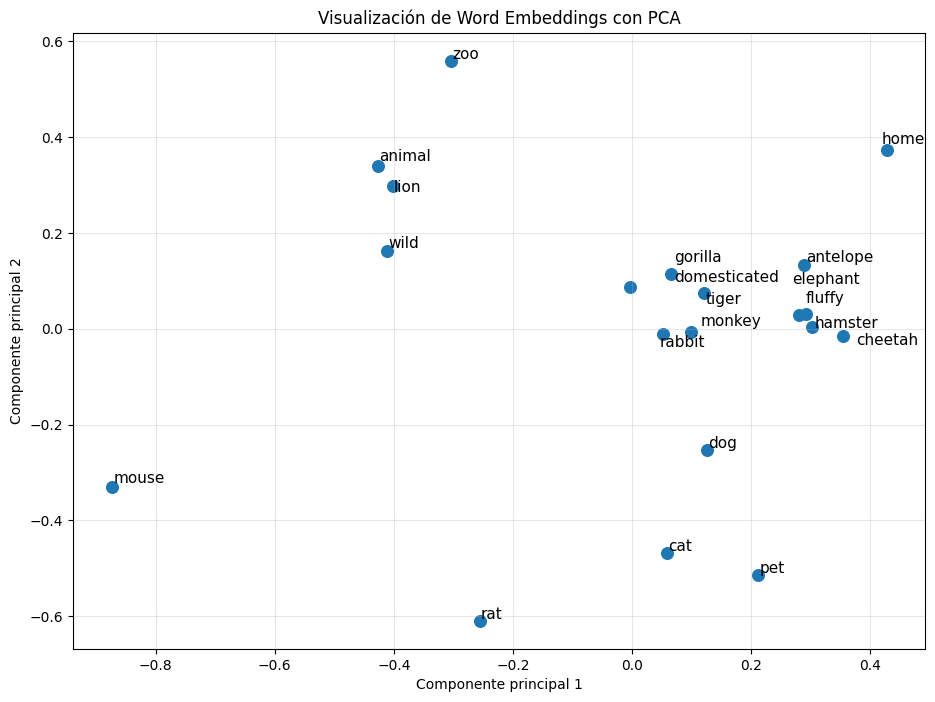

In [8]:
pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(embeddings)

pca_df = pd.DataFrame(coords_pca, columns=['PC1', 'PC2'])
pca_df['word'] = words

plt.figure(figsize=(11, 8))
plt.scatter(pca_df['PC1'], pca_df['PC2'], s=70)
texts = []
for _, row in pca_df.iterrows():
    texts.append(plt.text(row['PC1'], row['PC2'], row['word'], fontsize=11))
adjust_text(texts)
plt.title('Visualización de Word Embeddings con PCA')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.grid(True, alpha=0.3)
plt.show()

## 9. Extensión: embeddings contextuales

Hasta ahora, cada palabra tiene **un solo vector fijo**, sin importar la oración donde aparezca. Los modelos modernos (BERT, GPT y los LLM actuales) generan vectores **contextuales**: el vector de una palabra cambia según las palabras que la rodean.

Para verlo, usamos la palabra `bank` (que significa *banco* de dinero o *orilla* de un río) en tres oraciones distintas y comparamos sus vectores a la salida del modelo (última capa).

In [9]:
def get_contextual_embedding(sentence, target_word, tokenizer, model):
    """Devuelve el vector contextual (última capa) de `target_word` dentro de `sentence`."""
    enc = tokenizer(sentence, return_tensors='pt')
    target_ids = tokenizer(target_word, add_special_tokens=False)['input_ids']
    ids = enc['input_ids'][0].tolist()

    # Buscar la posición de los subtokens de la palabra objetivo en la oración
    start = next(i for i in range(len(ids) - len(target_ids) + 1)
                 if ids[i:i + len(target_ids)] == target_ids)

    with torch.no_grad():
        hidden = model(**enc).last_hidden_state[0]   # (n_tokens, dimensión)

    return hidden[start:start + len(target_ids)].mean(dim=0).numpy()

sentences = {
    'dinero_1': 'I deposited my salary at the bank this morning.',
    'dinero_2': 'The bank approved my loan yesterday.',
    'rio':      'We had a picnic on the bank of the river.',
}

ctx_vectors = {k: get_contextual_embedding(s, 'bank', tokenizer, model) for k, s in sentences.items()}
ctx_df = pd.DataFrame(
    cosine_similarity(np.vstack(list(ctx_vectors.values()))),
    index=ctx_vectors.keys(), columns=ctx_vectors.keys()
).round(3)
ctx_df

,dinero_1,dinero_2,rio
dinero_1,1.000,0.737,0.626
dinero_2,0.737,1.000,0.566
rio,0.626,0.566,1.000


Observa que las dos oraciones sobre el banco financiero (`dinero_1` y `dinero_2`) tienen una similitud mayor entre sí que con la oración del río. Es decir, el modelo **distingue el significado de `bank` según el contexto**, algo que un embedding fijo no puede hacer. Esta es la base de cómo los LLM actuales (GPT, Gemini, Llama, etc.) entienden el lenguaje.

## Conclusión

Los **Word Embeddings** permiten representar palabras como vectores densos. Cuando dos palabras aparecen en contextos similares o tienen relaciones semánticas cercanas, sus vectores tienden a quedar próximos en el espacio vectorial. Esta idea es fundamental en PLN, búsqueda semántica, clasificación de textos, recuperación de información y sistemas RAG.